In [2]:
import pandas as pd


In [12]:
from google.colab import files

uploaded = files.upload()

Saving credit_risk_dataset  Backup 1.csv to credit_risk_dataset  Backup 1.csv
Saving excel 2.csv to excel 2.csv
Saving excel 3.csv to excel 3.csv


In [13]:
df = pd.read_csv("excel 3.csv")

In [14]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,20,64000,RENT,3.0,VENTURE,D,16000,15.31,1,0.25,Y,4
1,20,32652,MORTGAGE,0.0,PERSONAL,D,6000,14.61,1,0.18,N,4
2,20,94000,RENT,4.0,EDUCATION,D,5000,16.02,0,0.05,N,3
3,20,42000,RENT,4.0,VENTURE,B,6500,11.71,0,0.15,N,2
4,20,34800,RENT,3.0,MEDICAL,C,7000,13.61,0,0.20,Y,2


In [16]:
df.shape

(32581, 12)

In [17]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [18]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [19]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [20]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [21]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


In [25]:
df.groupby('age_group')['loan_status'].sum()

/tmp/ipykernel_3342/2239647668.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')['loan_status'].sum()


,loan_status
age_group,
<25,3535
25-34,2846
35-44,583
45-54,112
55-64,27
65+,5


In [29]:
df.groupby('income_category')['loan_status'].sum()

/tmp/ipykernel_3342/4218381631.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('income_category')['loan_status'].sum()


,loan_status
income_category,
Low,3236
Medium,1755
High,1375
Very High,742


In [31]:
df.groupby('loan_grade')['loan_status'].sum().sort_values(ascending=False)

,loan_status
loan_grade,
D,2141
B,1701
C,1339
A,1073
E,621
F,170
G,63


In [32]:
df.groupby('loan_intent')['loan_status'].sum().sort_values(ascending=False)

,loan_status
loan_intent,
MEDICAL,1621
DEBTCONSOLIDATION,1490
EDUCATION,1111
PERSONAL,1098
HOMEIMPROVEMENT,941
VENTURE,847


In [33]:
df.groupby('cb_person_default_on_file')['loan_status'].sum()

,loan_status
cb_person_default_on_file,
N,4936
Y,2172


In [34]:
df.groupby('person_home_ownership')['loan_status'].sum().sort_values(ascending=False)

,loan_status
person_home_ownership,
RENT,5192
MORTGAGE,1690
OWN,193
OTHER,33


In [35]:
df[df['loan_status']==1]['person_income'].mean()

np.float64(49125.65222284749)

In [36]:
df[df['loan_status']==1]['loan_amnt'].mean()


np.float64(10850.502954417558)

In [37]:
df.corr(numeric_only=True)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
person_age,1.000000,0.173202,0.163106,0.050787,0.012580,-0.021629,-0.042411,0.859133
person_income,0.173202,1.000000,0.134268,0.266820,0.000792,-0.144449,-0.254471,0.117987
person_emp_length,0.163106,0.134268,1.000000,0.113082,-0.056405,-0.082489,-0.054111,0.144699
loan_amnt,0.050787,0.266820,0.113082,1.000000,0.146813,0.105376,0.572612,0.041967
loan_int_rate,0.012580,0.000792,-0.056405,0.146813,1.000000,0.335133,0.120314,0.016696
loan_status,-0.021629,-0.144449,-0.082489,0.105376,0.335133,1.000000,0.379366,-0.015529
loan_percent_income,-0.042411,-0.254471,-0.054111,0.572612,0.120314,0.379366,1.000000,-0.031690
cb_person_cred_hist_length,0.859133,0.117987,0.144699,0.041967,0.016696,-0.015529,-0.031690,1.000000


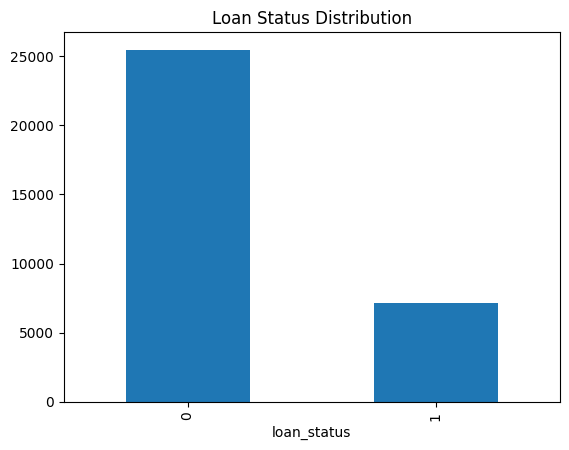

In [38]:
import matplotlib.pyplot as plt

df['loan_status'].value_counts().plot(kind='bar')
plt.title('Loan Status Distribution')
plt.show()

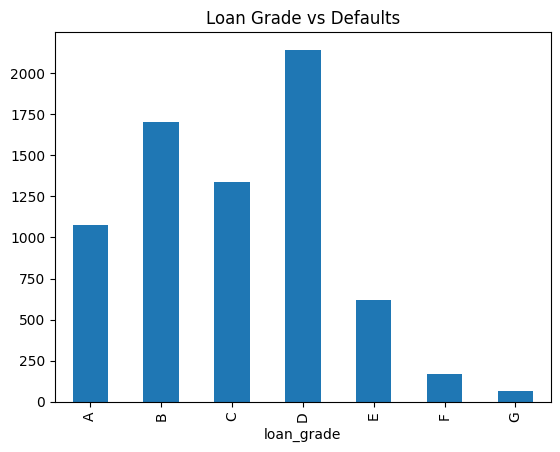

In [39]:
df.groupby('loan_grade')['loan_status'].sum().plot(kind='bar')
plt.title('Loan Grade vs Defaults')
plt.show()

/tmp/ipykernel_3342/1324375830.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')['loan_status'].sum().plot(kind='bar')


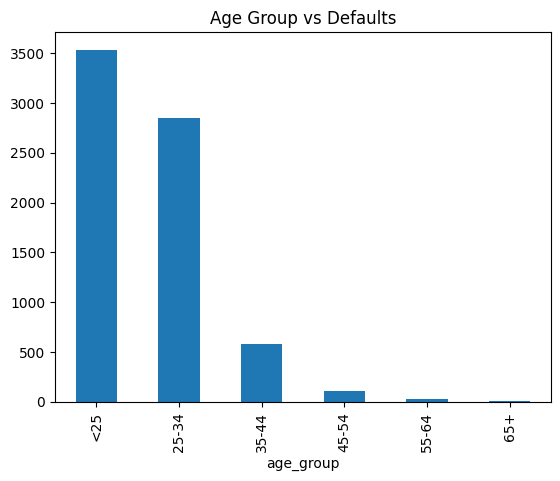

In [40]:
df.groupby('age_group')['loan_status'].sum().plot(kind='bar')
plt.title('Age Group vs Defaults')
plt.show()

/tmp/ipykernel_3342/4004767278.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('income_category')['loan_status'].sum().plot(kind='bar')


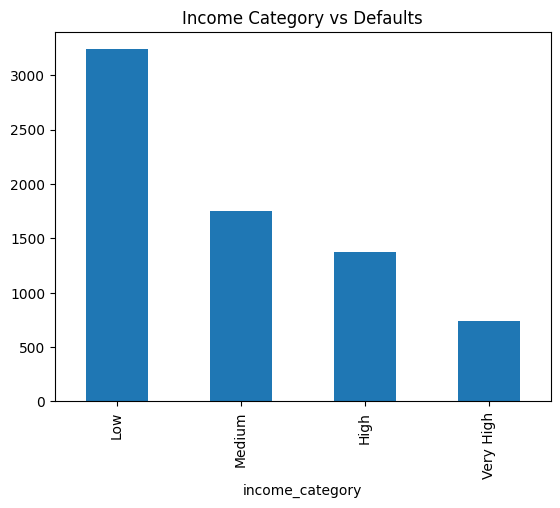

In [41]:
df.groupby('income_category')['loan_status'].sum().plot(kind='bar')
plt.title('Income Category vs Defaults')
plt.show()